## 1. Install Dependencies & Login

In [1]:
!pip install -q bert-score tokenizers ijson
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Logged in.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 4.5 MB/s eta 0:00:00


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in.


## 2. Check GPU

In [2]:
import torch
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CUDA: True
GPU: Tesla T4
VRAM: 15.6 GB
Device: cuda


## 3. Configuration — Efficient GQA Transformer

**Architecture:** 16-layer Transformer with:
- **Grouped Query Attention (GQA):** 12 query heads, 2 KV heads → 6x smaller KV cache.
- **Alternating attention:** Even layers use sliding window (w=256) for local patterns, odd layers use full attention for global context.
- **RoPE + RMSNorm + SwiGLU**.
- Deeper (16L) than the 12L baseline, since GQA saves parameters/memory in attention.

In [3]:
import os, random, json, time, math, zipfile, numpy as np
from tqdm.auto import tqdm
SEED = 42; random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
SOURCE_WEIGHTS = {"train_supreme_court.json": 0.40, "train_high_courts.json": 0.30,
    "train_acts.json": 0.15, "train_tribunals.json": 0.15}
TEST_FILE = "Phase_1_Pretraining/Test/test.json"
# === Model: Efficient GQA Transformer ===
VOCAB_SIZE = 32000; D_MODEL = 768; N_LAYERS = 16; N_HEADS = 12
N_KV_HEADS = 2  # Grouped Query Attention: 2 KV groups for 12 Q heads
HEAD_DIM = D_MODEL // N_HEADS; D_FF = 2048; MAX_SEQ_LEN = 1024
ROPE_BASE = 10000.0; DROPOUT = 0.0
WINDOW_SIZE = 256  # Sliding window for alternating layers

# --- SESSION CONTROL ---
SESSION_ID = 2  # Change to 2, 3, or 4 for subsequent runs
SESSION_TOKENS = 500_000_000

# --- Training Constants ---
# Set to 2 Billion so the LR decays smoothly over all 4 sessions combined
TOTAL_TOKENS = 2_000_000_000  
BLOCK_SIZE = 1024; BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 4; PEAK_LR = 6e-4; MIN_LR = 6e-6
WARMUP_STEPS = 1000; WEIGHT_DECAY = 0.1; BETA1 = 0.9; BETA2 = 0.95; GRAD_CLIP = 1.0

# # === Training ===
# TOTAL_TOKENS = 500_000_000; BLOCK_SIZE = 1024; BATCH_SIZE = 16
# GRADIENT_ACCUMULATION_STEPS = 4; PEAK_LR = 6e-4; MIN_LR = 6e-6
# WARMUP_STEPS = 1000; WEIGHT_DECAY = 0.1; BETA1 = 0.9; BETA2 = 0.95; GRAD_CLIP = 1.0

VAL_TOKENS = 5_000_000; VAL_INTERVAL_STEPS = 500; VAL_FRACTION = 0.03
TARGET_GENERATION_WORDS = 128; MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.5; TOP_P = 0.9; TOP_K = 50; REPETITION_PENALTY = 1.1
SAVE_INTERVAL_STEPS = 500; SAVE_TOTAL_LIMIT = 3
TOKENIZER_VOCAB_SIZE = 32000; TOKENIZER_MIN_FREQ = 2; TOKENIZER_SAMPLE_SIZE = 200_000
TOKENIZER_DIR = "/kaggle/working/legal_tokenizer_efficient"
OUTPUT_DIR = "/kaggle/working/cs781_efficient"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-efficient-final")
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
for d in [OUTPUT_DIR, MODEL_OUTPUT_DIR, CHECKPOINT_DIR, TOKENIZER_DIR]: os.makedirs(d, exist_ok=True)
print(f"Efficient: {N_LAYERS}L, d={D_MODEL}, GQA({N_HEADS}Q/{N_KV_HEADS}KV), window={WINDOW_SIZE}")

Efficient: 16L, d=768, GQA(12Q/2KV), window=256


In [4]:
import os
import numpy as np
from transformers import PreTrainedTokenizerFast

TOK_DIR = "/kaggle/input/datasets/paveetsaluja/m4-dataset-500m/legal_tokenizer_efficient"
TRAIN_BIN = "/kaggle/input/datasets/vivekchandwani7/m4-highcourt-data/cs781_efficient/train_tokens.bin"
VAL_BIN = "/kaggle/input/datasets/vivekchandwani7/m4-highcourt-data/cs781_efficient/val_tokens.bin"

# Point this to the output of your previous session (e.g., Session 1's best.pt for Session 2)
CHECKPOINT_PATH = "/kaggle/input/datasets/vivekchandwani7/m4extender/cs781_efficient/checkpoints/best.pt"

print("Loading tokenizer...")
tokenizer = PreTrainedTokenizerFast.from_pretrained(TOK_DIR)
VOCAB_SIZE = len(tokenizer)

print("Loading memory-mapped arrays...")
# Omitting the 'shape' argument lets memmap auto-detect the exact length from the file size on disk
full_train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="r")
val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="r")

# Since the generation script truncated the files, the length is exactly the valid token count
full_train_ptr = len(full_train_mmap)
val_ptr = len(val_mmap)

# --- SESSION SLICING LOGIC ---
start_idx = (SESSION_ID - 1) * SESSION_TOKENS
end_idx = SESSION_ID * SESSION_TOKENS

if start_idx >= full_train_ptr:
    raise ValueError(f"Not enough tokens in dataset for Session {SESSION_ID}. Total available: {full_train_ptr:,}")

end_idx = min(end_idx, full_train_ptr)
session_train_mmap = full_train_mmap[start_idx:end_idx]

print(f"Global Train Tokens Available: {full_train_ptr:,}")
print(f"Session {SESSION_ID} Active: Loaded {len(session_train_mmap):,} tokens (Indices: {start_idx:,} -> {end_idx:,})")
print(f"Val: {len(val_mmap):,} tokens")

Loading tokenizer...
Loading memory-mapped arrays...
Global Train Tokens Available: 2,000,000,000
Session 2 Active: Loaded 500,000,000 tokens (Indices: 500,000,000 -> 1,000,000,000)
Val: 5,000,000 tokens


In [5]:
# import os
# import numpy as np
# from transformers import PreTrainedTokenizerFast
# from huggingface_hub import hf_hub_download

# # 1. Define Dataset Paths (Model 4)
# DATASET_PATH = "/kaggle/input/datasets/paveetsaluja/m4-dataset-500m"
# TOK_DIR = os.path.join(DATASET_PATH, "legal_tokenizer_efficient")
# TRAIN_BIN = os.path.join(DATASET_PATH, "cs781_efficient", "train_tokens.bin")
# VAL_BIN = os.path.join(DATASET_PATH, "cs781_efficient", "val_tokens.bin")

# # 2. Load Tokenizer & Set Constants
# print("Loading tokenizer from dataset...")
# tokenizer = PreTrainedTokenizerFast.from_pretrained(TOK_DIR)
# VOCAB_SIZE = len(tokenizer)
# EOS_ID = tokenizer.eos_token_id
# PAD_ID = tokenizer.pad_token_id
# print(f"VOCAB_SIZE={VOCAB_SIZE}, EOS={EOS_ID}, PAD={PAD_ID}")

# # 3. Load Memory-Mapped Token Binaries
# # mode="r" is required since Kaggle dataset inputs are read-only
# print("Loading memory-mapped arrays...")
# train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="r")
# val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="r")

# # Strip any trailing zeros if the original quota wasn't 100% perfectly met
# train_ptr = np.max(np.nonzero(train_mmap)) + 1
# val_ptr = np.max(np.nonzero(val_mmap)) + 1

# train_mmap = train_mmap[:train_ptr]
# val_mmap = val_mmap[:val_ptr]

# print(f"Train: {len(train_mmap):,} tokens")
# print(f"Val: {len(val_mmap):,} tokens")

# # 4. Download Test File 
# # (Required for the generation step later in the notebook)
# print("\nDownloading test file...")
# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO, 
#     filename=TEST_FILE, 
#     repo_type="dataset", 
#     token=HF_TOKEN
# )
# print(f"Test file ready: {test_file_path}")

## 4. Download Data

In [6]:
# from huggingface_hub import hf_hub_download
# train_file_paths = {}
# for tf in TRAIN_FILES:
#     path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=tf, repo_type="dataset", token=HF_TOKEN)
#     source_name = os.path.basename(tf)
#     train_file_paths[source_name] = path
#     print(f"Downloaded {source_name}: {path}")
# test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN)
# print(f"\nTest file: {test_file_path}")

## 5. Train BPE Tokenizer

In [7]:
# from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
# from transformers import PreTrainedTokenizerFast
# import ijson, gc
# # --- Collect texts via streaming (reservoir sampling per source) ---
# print("Collecting texts for tokenizer training via weighted streaming...")
# tokenizer_quotas = {k: int(TOKENIZER_SAMPLE_SIZE * v) for k, v in SOURCE_WEIGHTS.items()}
# tokenizer_texts = []
# random.seed(SEED)
# for source_name, fpath in train_file_paths.items():
#     target = tokenizer_quotas.get(source_name, 0)
#     sampled = []
#     seen = 0
#     with open(fpath, "rb") as f:
#         for rec in tqdm(ijson.items(f, "item"), desc=f"Streaming {source_name}", unit=" docs"):
#             text = rec.get("text", "")
#             if not text.strip(): continue
#             if seen < target: sampled.append(text)
#             else:
#                 j = random.randint(0, seen)
#                 if j < target: sampled[j] = text
#             seen += 1
#     tokenizer_texts.extend(sampled)
#     print(f"  {source_name}: sampled {len(sampled)} from {seen}")
# print(f"Total tokenizer docs: {len(tokenizer_texts)}")
# # Write to temp file
# tok_file = os.path.join(TOKENIZER_DIR, "corpus.txt")
# with open(tok_file, "w", encoding="utf-8") as f:
#     for t in tqdm(tokenizer_texts, desc="Writing"):
#         c = t.replace("\n", " ").replace("\r", " ").strip()
#         if c: f.write(c + "\n")
# del tokenizer_texts; gc.collect()
# # Train BPE
# print(f"\nTraining BPE (vocab={TOKENIZER_VOCAB_SIZE})...")
# SPECIAL_TOKENS = ["<|pad|>", "<|eos|>", "<|bos|>", "<|unk|>"]
# tok = Tokenizer(models.BPE(unk_token="<|unk|>"))
# tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
# tok.decoder = decoders.ByteLevel()
# tok.post_processor = processors.ByteLevel(trim_offsets=True)
# trainer_obj = trainers.BpeTrainer(vocab_size=TOKENIZER_VOCAB_SIZE, min_frequency=TOKENIZER_MIN_FREQ,
#     special_tokens=SPECIAL_TOKENS, show_progress=True, initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
# tok.train(files=[tok_file], trainer=trainer_obj)
# print(f"Vocab size: {tok.get_vocab_size()}")
# tok.save(os.path.join(TOKENIZER_DIR, "tokenizer.json"))
# tokenizer = PreTrainedTokenizerFast(tokenizer_object=tok, unk_token="<|unk|>",
#     eos_token="<|eos|>", bos_token="<|bos|>", pad_token="<|pad|>")
# tokenizer.save_pretrained(TOKENIZER_DIR)
# VOCAB_SIZE = len(tokenizer)
# EOS_ID = tokenizer.eos_token_id
# PAD_ID = tokenizer.pad_token_id
# print(f"VOCAB_SIZE={VOCAB_SIZE}, EOS={EOS_ID}, PAD={PAD_ID}")
# # Quick check
# for s in ["The appellant herein is the original plaintiff.", "Section 302 of the Indian Penal Code"]:
#     ids = tokenizer.encode(s, add_special_tokens=False)
#     assert tokenizer.decode(ids).strip() == s.strip()
# print("Tokenizer OK!")
# if os.path.exists(tok_file): os.remove(tok_file)

## 6. Tokenize & Save to Binary (Memory-Mapped)

In [8]:
# import ijson, gc
# TRAIN_BIN = os.path.join(OUTPUT_DIR, "train_tokens.bin")
# VAL_BIN = os.path.join(OUTPUT_DIR, "val_tokens.bin")
# random.seed(SEED)
# train_quotas = {k: int(TOTAL_TOKENS * v) for k, v in SOURCE_WEIGHTS.items()}
# val_quotas = {k: int(VAL_TOKENS * v) for k, v in SOURCE_WEIGHTS.items()}
# train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="w+", shape=(TOTAL_TOKENS,))
# val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="w+", shape=(VAL_TOKENS,))
# train_ptr = 0; val_ptr = 0
# print(f"Targeting {TOTAL_TOKENS:,} train + {VAL_TOKENS:,} val tokens")
# with tqdm(total=TOTAL_TOKENS+VAL_TOKENS, desc="Tokenizing", unit="tok", unit_scale=True) as pbar:
#     for src, fpath in train_file_paths.items():
#         t_quota = train_quotas[src]; v_quota = val_quotas[src]
#         t_done = 0; v_done = 0
#         with open(fpath, "rb") as f:
#             for rec in ijson.items(f, "item"):
#                 toks = tokenizer.encode(rec["text"], add_special_tokens=False) + [EOS_ID]  # EOS marks doc boundary
#                 if random.random() < VAL_FRACTION:
#                     if v_done < v_quota:
#                         n = min(len(toks), v_quota - v_done, VAL_TOKENS - val_ptr)
#                         if n > 0:
#                             val_mmap[val_ptr:val_ptr+n] = toks[:n]
#                             val_ptr += n; v_done += n; pbar.update(n)
#                 else:
#                     if t_done < t_quota:
#                         n = min(len(toks), t_quota - t_done, TOTAL_TOKENS - train_ptr)
#                         if n > 0:
#                             train_mmap[train_ptr:train_ptr+n] = toks[:n]
#                             train_ptr += n; t_done += n; pbar.update(n)
#                 if t_done >= t_quota and v_done >= v_quota: break
# train_mmap.flush(); val_mmap.flush(); del train_mmap, val_mmap
# print(f"Train: {train_ptr:,} tokens, Val: {val_ptr:,} tokens")
# print(f"Train file: {train_ptr*4/1e9:.2f} GB, Val file: {val_ptr*4/1e9:.2f} GB")
# # Re-open read-only (only the filled portion)
# train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="r")[:train_ptr]
# val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="r")[:val_ptr]
# gc.collect()

## 7. DataLoader & LR Scheduler

In [9]:
from torch.utils.data import IterableDataset, DataLoader, get_worker_info
class WSDScheduler:
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_frac=0.10):
        self.peak_lr = peak_lr; self.min_lr = min_lr; self.warmup_steps = warmup_steps
        self.total_steps = total_steps; self.decay_start = int(total_steps * (1 - decay_frac))
        self.decay_steps = total_steps - self.decay_start
    def get_lr(self, step):
        if step < self.warmup_steps: return self.peak_lr * step / max(self.warmup_steps, 1)
        if step < self.decay_start: return self.peak_lr
        p = (step - self.decay_start) / max(self.decay_steps, 1)
        return self.min_lr + (self.peak_lr - self.min_lr) * 0.5 * (1 + math.cos(math.pi * p))

class BlockDataset(IterableDataset):
    def __init__(self, mmap_tokens, block_size, batch_size, seed=42):
        self.mmap = mmap_tokens; self.block_size = block_size
        self.batch_size = batch_size; self.seed = seed; self.epoch = 0
        self.num_blocks = len(mmap_tokens) // block_size
        print(f"  BlockDataset: {self.num_blocks:,} blocks of {block_size}")
    def __iter__(self):
        info = get_worker_info()
        wid, nw = (info.id, info.num_workers) if info else (0, 1)
        # Same shuffle in every worker, then each worker takes a disjoint shard (no duplicated data)
        rng = random.Random(self.seed + self.epoch)
        indices = list(range(self.num_blocks)); rng.shuffle(indices)
        indices = indices[wid::nw]
        self.epoch += 1
        batch = []
        for idx in indices:
            s = idx * self.block_size
            batch.append(self.mmap[s:s+self.block_size].astype(np.int64))
            if len(batch) == self.batch_size:
                yield torch.tensor(np.array(batch), dtype=torch.long)
                batch = []

# tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
# TOTAL_STEPS = TOTAL_TOKENS // tokens_per_step
# lr_scheduler = WSDScheduler(PEAK_LR, MIN_LR, WARMUP_STEPS, TOTAL_STEPS)
# print(f"Total steps: {TOTAL_STEPS:,}")
# train_dataset = BlockDataset(train_mmap, BLOCK_SIZE, BATCH_SIZE, SEED)
# train_loader = DataLoader(train_dataset, batch_size=None, num_workers=2, pin_memory=True, prefetch_factor=2)

tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
GLOBAL_TOTAL_STEPS = TOTAL_TOKENS // tokens_per_step
SESSION_STEPS = len(session_train_mmap) // tokens_per_step

# The scheduler spans GLOBAL_TOTAL_STEPS to ensure continuous decay across all sessions
lr_scheduler = WSDScheduler(PEAK_LR, MIN_LR, WARMUP_STEPS, GLOBAL_TOTAL_STEPS)
print(f"Global total steps: {GLOBAL_TOTAL_STEPS:,} | Steps this session: {SESSION_STEPS:,}")

# Pass session_train_mmap instead of train_mmap. Change seed slightly per session.
train_dataset = BlockDataset(session_train_mmap, BLOCK_SIZE, BATCH_SIZE, SEED + SESSION_ID)
train_loader = DataLoader(train_dataset, batch_size=None, num_workers=2, pin_memory=True, prefetch_factor=2)

Global total steps: 30,517 | Steps this session: 7,629
  BlockDataset: 488,281 blocks of 1024


## 8. Model Components: RMSNorm + RoPE + SwiGLU

In [10]:
import torch.nn as nn
import torch.nn.functional as F
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).type_as(x) * self.weight

def precompute_rope_freqs(dim, max_seq_len, base=10000.0):
    freqs = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(t, freqs)
    return torch.cos(freqs), torch.sin(freqs)

def apply_rope(x, freqs_cos, freqs_sin):
    x_r = x.reshape(*x.shape[:-1], -1, 2)
    x0, x1 = x_r[..., 0], x_r[..., 1]
    seq_len = x.shape[2]
    cos = freqs_cos[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    sin = freqs_sin[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    out0 = x0 * cos - x1 * sin
    out1 = x0 * sin + x1 * cos
    return torch.stack([out0, out1], dim=-1).reshape_as(x)

class SwiGLU_FFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        self.w_gate = nn.Linear(d_model, d_ff, bias=False)
        self.w_up = nn.Linear(d_model, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.w_down(F.silu(self.w_gate(x)) * self.w_up(x)))

## 9. Grouped Query Attention (GQA) with Sliding Window

- **GQA:** 2 KV head groups shared among 12 query heads via `repeat_kv`.
- **Sliding window:** Even-numbered layers restrict attention to the last 256 tokens. Odd layers see the full sequence. The same window is applied during cached decoding.

In [11]:
def repeat_kv(x, n_rep):
    """Repeat KV heads to match query heads. x: (B, n_kv_heads, T, D) -> (B, n_heads, T, D)"""
    if n_rep == 1: return x
    B, H, T, D = x.shape
    return x[:, :, None, :, :].expand(B, H, n_rep, T, D).reshape(B, H * n_rep, T, D)

class GQAttention(nn.Module):
    """Grouped Query Attention with optional sliding window."""
    def __init__(self, d_model, n_heads, n_kv_heads, head_dim, dropout=0.0, use_window=False, window_size=256):
        super().__init__()
        self.n_heads = n_heads; self.n_kv_heads = n_kv_heads
        self.head_dim = head_dim; self.n_rep = n_heads // n_kv_heads
        self.use_window = use_window; self.window_size = window_size
        self.attn_p = dropout
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        self.resid_dropout = nn.Dropout(dropout)
    def forward(self, x, freqs_cos, freqs_sin, use_cache=False, past_kv=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        if past_kv is not None:
            k = torch.cat([past_kv[0], k], dim=2)
            v = torch.cat([past_kv[1], v], dim=2)
        new_kv = (k, v) if use_cache else None   # cache stores only n_kv_heads (the GQA memory saving)
        dp = self.attn_p if self.training else 0.0
        if past_kv is not None:
            # Cached single-token decode. Window layers only look at the last `window_size` keys,
            # matching the training-time sliding-window mask.
            if self.use_window:
                k = k[:, :, -self.window_size:]; v = v[:, :, -self.window_size:]
            k = repeat_kv(k, self.n_rep); v = repeat_kv(v, self.n_rep)
            out = F.scaled_dot_product_attention(q, k, v, dropout_p=dp)
        else:
            k = repeat_kv(k, self.n_rep); v = repeat_kv(v, self.n_rep)
            if self.use_window and T > 1:
                # Boolean sliding-window causal mask (True = may attend)
                row = torch.arange(T, device=x.device).unsqueeze(1)
                col = torch.arange(T, device=x.device).unsqueeze(0)
                mask = (col <= row) & (col > row - self.window_size)
                out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=dp)
            else:
                out = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=dp)
        out = out.transpose(1, 2).contiguous().view(B, T, -1)
        return self.resid_dropout(self.out_proj(out)), new_kv

## 10. Transformer Block

In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, head_dim, d_ff, dropout=0.0,
                 use_window=False, window_size=256):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attn = GQAttention(d_model, n_heads, n_kv_heads, head_dim, dropout, use_window, window_size)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    def forward(self, x, freqs_cos, freqs_sin, use_cache=False, past_kv=None):
        attn_out, new_kv = self.attn(self.attn_norm(x), freqs_cos, freqs_sin, use_cache, past_kv)
        x = x + attn_out
        x = x + self.ffn(self.ffn_norm(x))
        return x, new_kv

## 11. Full Model: EfficientLegalLM

In [13]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint
class EfficientLegalLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, n_kv_heads, head_dim, d_ff,
                 max_seq_len, rope_base=10000.0, dropout=0.0, window_size=256, use_gc=True):
        super().__init__()
        self.d_model = d_model; self.n_layers = n_layers; self.vocab_size = vocab_size
        self.max_seq_len = max_seq_len; self.use_gc = use_gc
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        # Alternating layers: even = sliding window, odd = full attention
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_heads, head_dim, d_ff, dropout,
                use_window=(i % 2 == 0), window_size=window_size)
            for i in range(n_layers)
        ])
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight
        fc, fs = precompute_rope_freqs(head_dim, max_seq_len, rope_base)
        self.register_buffer("freqs_cos", fc, persistent=False)
        self.register_buffer("freqs_sin", fs, persistent=False)
        self._init_weights()
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                torch.nn.init.normal_(m.weight, std=0.02)
                if m.bias is not None: torch.nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                torch.nn.init.normal_(m.weight, std=0.02)
        for layer in self.layers:
            s = 0.02 / math.sqrt(2 * self.n_layers)
            torch.nn.init.normal_(layer.attn.out_proj.weight, std=s)
            torch.nn.init.normal_(layer.ffn.w_down.weight, std=s)
    def forward(self, input_ids, targets=None, use_cache=False, past_kvs=None):
        B, T = input_ids.shape
        x = self.emb_dropout(self.tok_emb(input_ids))
        past_len = past_kvs[0][0].shape[2] if past_kvs is not None else 0
        fc = self.freqs_cos[past_len:past_len+T]
        fs = self.freqs_sin[past_len:past_len+T]
        presents = [] if use_cache else None
        for i, layer in enumerate(self.layers):
            pkv = past_kvs[i] if past_kvs is not None else None
            if self.use_gc and self.training:
                x, _ = grad_checkpoint(layer, x, fc, fs, False, None, use_reentrant=False)
            else:
                x, kv = layer(x, fc, fs, use_cache, pkv)
                if use_cache: presents.append(kv)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits[:, :-1, :].contiguous().view(-1, self.vocab_size),
                targets[:, 1:].contiguous().view(-1), ignore_index=-100)
        return logits, loss, presents
    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.7, top_p=0.9,
                 top_k=50, repetition_penalty=1.1, eos_token_id=None):
        self.eval(); B = input_ids.shape[0]
        generated = input_ids; past_kvs = None
        for _ in range(max_new_tokens):
            curr = generated[:, -1:] if past_kvs is not None else generated
            logits, _, past_kvs = self.forward(curr, use_cache=True, past_kvs=past_kvs)
            logits = logits[:, -1, :].float()
            if repetition_penalty != 1.0:
                for b in range(B):
                    idx = torch.unique(generated[b])
                    sel = logits[b, idx]
                    logits[b, idx] = torch.where(sel > 0, sel / repetition_penalty, sel * repetition_penalty)
            logits = logits / temperature
            if top_k > 0:
                topk_v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < topk_v[:, -1:]] = float('-inf')
            if top_p < 1.0:
                sl, si = torch.sort(logits, descending=True)
                cp = torch.cumsum(F.softmax(sl, dim=-1), dim=-1)
                rm = cp > top_p; rm[:, 1:] = rm[:, :-1].clone(); rm[:, 0] = False
                for b in range(B): logits[b, si[b][rm[b]]] = float('-inf')
            probs = F.softmax(logits, dim=-1)
            next_tok = torch.multinomial(probs, num_samples=1)
            generated = torch.cat([generated, next_tok], dim=1)
            if eos_token_id is not None and (next_tok == eos_token_id).all(): break
        return generated

model = EfficientLegalLM(VOCAB_SIZE, D_MODEL, N_LAYERS, N_HEADS, N_KV_HEADS, HEAD_DIM, D_FF,
    MAX_SEQ_LEN, ROPE_BASE, DROPOUT, WINDOW_SIZE, use_gc=True).to(device)
model = torch.compile(model)
total_params = sum(p.numel() for p in model.parameters())
unique_params = total_params - model.tok_emb.weight.numel()
print(f"Efficient GQA params (excl. tied embeddings): {unique_params:,} ({unique_params/1e6:.1f}M)")
assert 50_000_000 <= unique_params <= 300_000_000

Efficient GQA params (excl. tied embeddings): 97,542,912 (97.5M)


## 12. Optimizer & Mixed Precision

In [14]:
decay_p = []; no_decay_p = []
for name, p in model.named_parameters():
    if not p.requires_grad: continue
    if "norm" in name or "bias" in name or "tok_emb" in name: no_decay_p.append(p)
    else: decay_p.append(p)
optimizer = torch.optim.AdamW([{"params": decay_p, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay_p, "weight_decay": 0.0}], lr=PEAK_LR, betas=(BETA1, BETA2), fused=True)
scaler = torch.amp.GradScaler("cuda")
print(f"Optimizer: {len(decay_p)} decay + {len(no_decay_p)} no-decay params")

Optimizer: 112 decay + 34 no-decay params


## 13. Validation Function

In [15]:
@torch.no_grad()
def evaluate_val(model, val_mmap, block_size, device, max_batches=50):
    model.eval(); total_loss = 0.0; n = 0
    num_blocks = len(val_mmap) // block_size
    for i in range(0, min(num_blocks, max_batches * 8), 8):
        batch_blocks = []
        for j in range(i, min(i + 8, num_blocks)):
            batch_blocks.append(val_mmap[j*block_size:(j+1)*block_size].astype(np.int64))
        ids = torch.tensor(np.array(batch_blocks), dtype=torch.long, device=device)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss, _ = model(ids, targets=ids)
        total_loss += loss.item(); n += 1
        if n >= max_batches: break
    avg = total_loss / max(n, 1); ppl = math.exp(min(avg, 20))
    model.train(); return avg, ppl

## 14. Checkpoint Functions

In [16]:
def save_checkpoint(model, optimizer, scaler, step, loss, path):
    torch.save({"model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(), "step": step, "loss": loss}, path)
    print(f"  Checkpoint saved: step {step}, loss {loss:.4f}")

def load_checkpoint(path, model, optimizer=None, scaler=None):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    if optimizer and "optimizer_state_dict" in ckpt: optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if scaler and "scaler_state_dict" in ckpt: scaler.load_state_dict(ckpt["scaler_state_dict"])
    return ckpt["step"], ckpt.get("loss")

def cleanup_checkpoints(ckpt_dir, keep=3):
    ckpts = sorted([f for f in os.listdir(ckpt_dir) if f.startswith("step_") and f.endswith(".pt")],
        key=lambda x: int(x.split("_")[1].split(".")[0]))
    while len(ckpts) > keep: os.remove(os.path.join(ckpt_dir, ckpts.pop(0)))

## 15. Training Loop

In [17]:
model.train(); train_log = []; val_log = []
best_val_loss = float("inf"); start_step = 0

# Check working directory first (mid-session resume), fallback to the input dataset checkpoint
working_ckpt = os.path.join(CHECKPOINT_DIR, "best.pt")
ckpt_to_load = working_ckpt if os.path.exists(working_ckpt) else CHECKPOINT_PATH

if os.path.exists(ckpt_to_load):
    print(f"Resuming training from {ckpt_to_load}...")
    start_step, prev_loss = load_checkpoint(ckpt_to_load, model, optimizer, scaler)
    if prev_loss:
        best_val_loss = prev_loss
    print(f"Resumed at global step {start_step} (Best Val Loss: {best_val_loss:.4f})")

start_time = time.time(); running_loss = 0.0; 
tokens_seen = start_step * BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
train_iter = iter(train_loader)

# Determine the exact step this specific session should stop at
end_step = start_step + SESSION_STEPS

for step in tqdm(range(start_step, end_step), desc=f"Training Session {SESSION_ID}", initial=start_step, total=GLOBAL_TOTAL_STEPS):
    lr = lr_scheduler.get_lr(step)
    for pg in optimizer.param_groups: pg["lr"] = lr
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    
    for _ in range(GRADIENT_ACCUMULATION_STEPS):
        try: batch = next(train_iter)
        except StopIteration: train_iter = iter(train_loader); batch = next(train_iter)
        batch = batch.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss, _ = model(batch, targets=batch)
            loss_s = loss / GRADIENT_ACCUMULATION_STEPS
        scaler.scale(loss_s).backward()
        accum_loss += loss.item()
        
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(optimizer); scaler.update()
    
    avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS
    running_loss += avg_loss
    tokens_seen += BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
    
    if (step+1) % 100 == 0:
        rl = running_loss / 100
        train_log.append({"step": step+1, "loss": rl, "lr": lr})
        tqdm.write(f"Step {step+1}/{GLOBAL_TOTAL_STEPS} | Loss: {rl:.4f} | LR: {lr:.2e} | Tok: {tokens_seen/1e6:.0f}M")
        running_loss = 0.0
        
    if (step+1) % VAL_INTERVAL_STEPS == 0:
        vl, vp = evaluate_val(model, val_mmap, BLOCK_SIZE, device)
        val_log.append({"step": step+1, "val_loss": vl, "val_ppl": vp})
        tqdm.write(f"  VAL: loss={vl:.4f} ppl={vp:.2f}")
        if vl < best_val_loss:
            best_val_loss = vl; best_step = step + 1
            save_checkpoint(model, optimizer, scaler, step+1, vl, os.path.join(CHECKPOINT_DIR, "best.pt"))
            
    if (step+1) % SAVE_INTERVAL_STEPS == 0:
        save_checkpoint(model, optimizer, scaler, step+1, avg_loss, os.path.join(CHECKPOINT_DIR, f"step_{step+1}.pt"))
        cleanup_checkpoints(CHECKPOINT_DIR, SAVE_TOTAL_LIMIT)
        
total_time = time.time() - start_time
print(f"\nSession {SESSION_ID} Done! {total_time/3600:.2f}h, best val loss: {best_val_loss:.4f}")

Resuming training from /kaggle/input/datasets/vivekchandwani7/m4extender/cs781_efficient/checkpoints/best.pt...
Resumed at global step 14500 (Best Val Loss: 1.6756)


Training Session 2:  48%|####7     | 14500/30517 [00:00<?, ?it/s]

W1009 20:24:18.209000 23 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Step 14600/30517 | Loss: 1.9384 | LR: 6.00e-04 | Tok: 957M
Step 14700/30517 | Loss: 1.6255 | LR: 6.00e-04 | Tok: 963M
Step 14800/30517 | Loss: 1.5235 | LR: 6.00e-04 | Tok: 970M
Step 14900/30517 | Loss: 1.4655 | LR: 6.00e-04 | Tok: 976M
Step 15000/30517 | Loss: 1.4205 | LR: 6.00e-04 | Tok: 983M
  VAL: loss=2.1178 ppl=8.31
  Checkpoint saved: step 15000, loss 1.3909
Step 15100/30517 | Loss: 1.3964 | LR: 6.00e-04 | Tok: 990M
Step 15200/30517 | Loss: 1.3742 | LR: 6.00e-04 | Tok: 996M
Step 15300/30517 | Loss: 1.3649 | LR: 6.00e-04 | Tok: 1003M
Step 15400/30517 | Loss: 1.3229 | LR: 6.00e-04 | Tok: 1009M
Step 15500/30517 | Loss: 1.3123 | LR: 6.00e-04 | Tok: 1016M
  VAL: loss=2.4435 ppl=11.51
  Checkpoint saved: step 15500, loss 1.3317
Step 15600/30517 | Loss: 1.2881 | LR: 6.00e-04 | Tok: 1022M
Step 15700/30517 | Loss: 1.3077 | LR: 6.00e-04 | Tok: 1029M
Step 15800/30517 | Loss: 1.2684 | LR: 6.00e-04 | Tok: 1035M
Step 15900/30517 | Loss: 1.2632 | LR: 6.00e-04 | Tok: 1042M
Step 16000/30517 | Los

In [18]:
# model.train(); train_log = []; val_log = []
# best_val_loss = float("inf"); best_step = 0
# start_time = time.time(); running_loss = 0.0; tokens_seen = 0
# train_iter = iter(train_loader)
# for step in tqdm(range(TOTAL_STEPS), desc="Training"):
#     lr = lr_scheduler.get_lr(step)
#     for pg in optimizer.param_groups: pg["lr"] = lr
#     optimizer.zero_grad(set_to_none=True)
#     accum_loss = 0.0
#     for _ in range(GRADIENT_ACCUMULATION_STEPS):
#         try: batch = next(train_iter)
#         except StopIteration: train_iter = iter(train_loader); batch = next(train_iter)
#         batch = batch.to(device, non_blocking=True)
#         with torch.amp.autocast("cuda", dtype=torch.float16):
#             _, loss, _ = model(batch, targets=batch)
#             loss_s = loss / GRADIENT_ACCUMULATION_STEPS
#         scaler.scale(loss_s).backward()
#         accum_loss += loss.item()
#     scaler.unscale_(optimizer)
#     torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
#     scaler.step(optimizer); scaler.update()
#     avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS
#     running_loss += avg_loss
#     tokens_seen += BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
#     if (step+1) % 100 == 0:
#         rl = running_loss / 100
#         train_log.append({"step": step+1, "loss": rl, "lr": lr})
#         tqdm.write(f"Step {step+1}/{TOTAL_STEPS} | Loss: {rl:.4f} | LR: {lr:.2e} | Tok: {tokens_seen/1e6:.0f}M")
#         running_loss = 0.0
#     if (step+1) % VAL_INTERVAL_STEPS == 0:
#         vl, vp = evaluate_val(model, val_mmap, BLOCK_SIZE, device)
#         val_log.append({"step": step+1, "val_loss": vl, "val_ppl": vp})
#         tqdm.write(f"  VAL: loss={vl:.4f} ppl={vp:.2f}")
#         if vl < best_val_loss:
#             best_val_loss = vl; best_step = step + 1
#             save_checkpoint(model, optimizer, scaler, step+1, vl, os.path.join(CHECKPOINT_DIR, "best.pt"))
#     if (step+1) % SAVE_INTERVAL_STEPS == 0:
#         save_checkpoint(model, optimizer, scaler, step+1, avg_loss, os.path.join(CHECKPOINT_DIR, f"step_{step+1}.pt"))
#         cleanup_checkpoints(CHECKPOINT_DIR, SAVE_TOTAL_LIMIT)
# total_time = time.time() - start_time
# print(f"\nDone! {total_time/3600:.2f}h, best val loss: {best_val_loss:.4f}")

## 16. Plot Loss

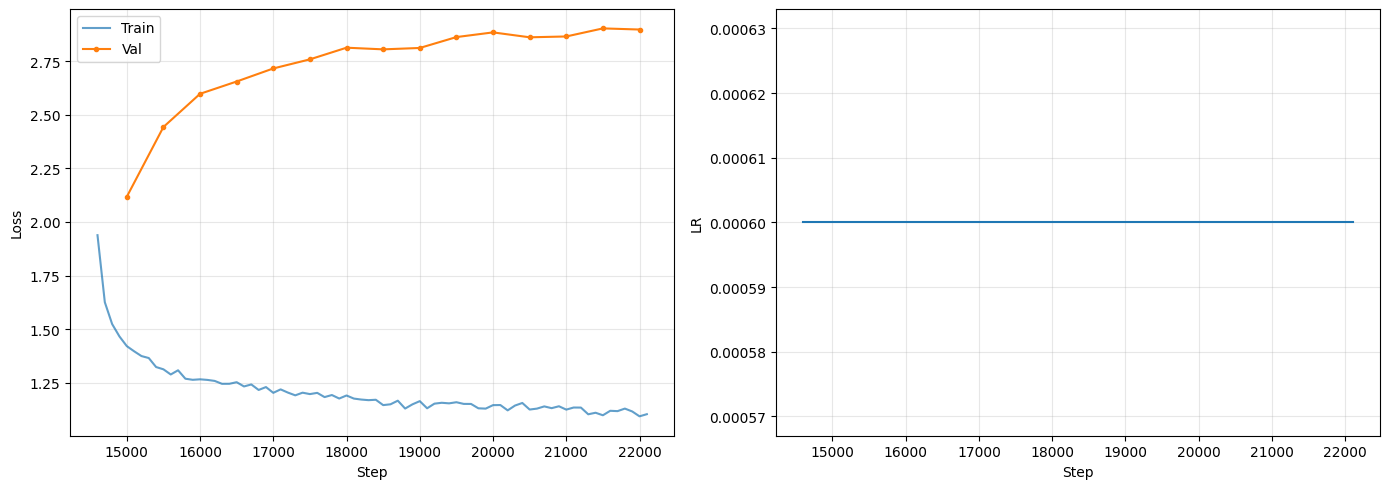

In [19]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot([d["step"] for d in train_log], [d["loss"] for d in train_log], label="Train", alpha=0.7)
ax1.plot([d["step"] for d in val_log], [d["val_loss"] for d in val_log], label="Val", marker="o", ms=3)
ax1.set_xlabel("Step"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot([d["step"] for d in train_log], [d["lr"] for d in train_log])
ax2.set_xlabel("Step"); ax2.set_ylabel("LR"); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=150); plt.show()

## 17. Load Best Checkpoint

In [20]:
print("Loading best checkpoint...")
load_checkpoint(os.path.join(CHECKPOINT_DIR, "best.pt"), model)
print("Best model loaded.")

Loading best checkpoint...


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/cs781_efficient/checkpoints/best.pt'

In [ ]:
fff

## 18. Load Test Prompts

In [ ]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print(f"Test examples: {len(test_data)}")

## 19. Generation Function

In [ ]:
def generate_continuations(prompts, model, tokenizer, device,
                           target_words=128, max_new_tokens=384,
                           temperature=0.5, top_p=0.9, top_k=50,
                           repetition_penalty=1.1, max_input_tokens=None):
    if max_input_tokens is None: max_input_tokens = MAX_SEQ_LEN - max_new_tokens
    model.eval(); results = []
    for prompt in tqdm(prompts, desc="Generating", leave=False):
        ids = tokenizer.encode(prompt, add_special_tokens=False)
        if len(ids) > max_input_tokens: ids = ids[-max_input_tokens:]
        inp = torch.tensor([ids], dtype=torch.long, device=device)
        inp_len = inp.shape[1]
        with torch.no_grad():
            out = model.generate(inp, max_new_tokens=max_new_tokens, temperature=temperature,
                top_p=top_p, top_k=top_k, repetition_penalty=repetition_penalty,
                eos_token_id=tokenizer.eos_token_id)
        gen_text = tokenizer.decode(out[0, inp_len:].tolist(), skip_special_tokens=True)
        results.append(" ".join(gen_text.split()[:target_words]))
    return results

## 20. Generate Predictions

In [ ]:
model.eval(); predictions = {}
items = list(test_data.items())
gen_start = time.time()
with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
    for idx, (eid, rec) in enumerate(tqdm(items, desc="Generating predictions")):
        cont = generate_continuations([rec["text"]], model, tokenizer, device,
            target_words=TARGET_GENERATION_WORDS, max_new_tokens=MAX_GENERATION_TOKENS,
            temperature=TEMPERATURE, top_p=TOP_P, top_k=TOP_K, repetition_penalty=REPETITION_PENALTY)[0]
        predictions[str(eid)] = {"text": cont}
gen_time = time.time() - gen_start
print(f"Generation: {gen_time:.0f}s ({gen_time/len(items):.2f}s/example)")

## 21. Save Model

In [ ]:
torch.save({"model_state_dict": model.state_dict(),
    "config": {"arch": "efficient_gqa", "vocab_size": VOCAB_SIZE, "d_model": D_MODEL,
        "n_layers": N_LAYERS, "n_heads": N_HEADS, "n_kv_heads": N_KV_HEADS,
        "d_ff": D_FF, "window_size": WINDOW_SIZE}
}, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
print(f"Model saved to {MODEL_OUTPUT_DIR}")

## 22. Save Predictions & Create ZIP

In [ ]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
assert set(str(k) for k in test_data.keys()) == set(predictions.keys()), "ID mismatch!"
print(f"Saved {len(predictions)} predictions")

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")
print(f"ZIP: {SUBMISSION_ZIP} ({os.path.getsize(SUBMISSION_ZIP)/1024:.1f} KB)")

## 23. Sample Quality Check

In [ ]:
print("=" * 80)
for eid, rec in list(test_data.items())[:3]:
    pred = predictions[str(eid)]["text"]
    print(f"\nID: {eid}")
    print(f"PROMPT (last 80 words): ...{' '.join(rec['text'].split()[-80:])}")
    print(f"GENERATED ({len(pred.split())} words): {pred[:300]}...")
    print("-" * 80)

## 24. Training Summary

In [ ]:
print("=" * 60)
print("EFFICIENT GQA TRANSFORMER SUMMARY")
print("=" * 60)
print(f"Architecture: GQA ({N_HEADS}Q/{N_KV_HEADS}KV) + Sliding Window (w={WINDOW_SIZE})")
print(f"Parameters (excl. tied embeddings): {unique_params/1e6:.1f}M")
print(f"Layers: {N_LAYERS}, Heads: {N_HEADS}, KV Heads: {N_KV_HEADS}, d_model: {D_MODEL}")
print(f"Attention pattern: even layers=window({WINDOW_SIZE}), odd layers=full")
print(f"Components: RoPE + RMSNorm + SwiGLU + Tied Embeddings")
print(f"Best val loss: {best_val_loss:.4f} (step {best_step})")
print(f"Training time: {total_time/3600:.2f}h")
print("=" * 60)